# Ejercicio — Hill Climbing
## Fundamentos de Inteligencia Artificial

Ahora trabajarás con una función un poco más compleja:

\[
f(x)=-((x-3)^2)((x-9)^2)+x
\]

Utiliza solamente valores enteros en:

\[
0 \leq x \leq 12
\]

El objetivo es utilizar Hill Climbing para encontrar un máximo.

### Importante

Esta función tiene más de una zona alta. Por ello, el punto donde comienza el algoritmo puede afectar el resultado.


## 1. Librería


In [2]:
import matplotlib.pyplot as plt


## 2. Define la función


In [3]:
def funcion(x):


    return -((x - 3)**2) * ((x - 9)**2) + x

## 3. Visualiza la función

Completa el código para calcular los valores de `f(x)` entre 0 y 12.


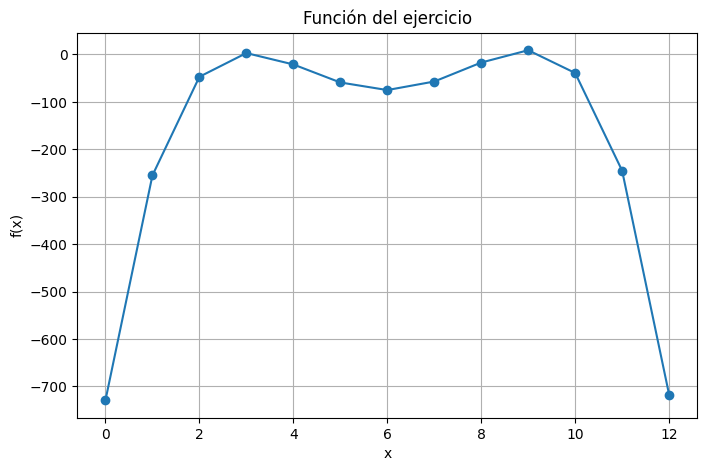

In [4]:
import matplotlib.pyplot as plt

valores_x = list(range(0, 13))

# Completa:
valores_y = [funcion(x) for x in valores_x]

plt.figure(figsize=(8, 5))
plt.plot(valores_x, valores_y, marker='o')
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Función del ejercicio")
plt.grid(True)
plt.show()

## 4. Implementa Hill Climbing

Tu algoritmo debe:

- recibir un punto inicial;
- generar los vecinos `x-1` y `x+1`;
- respetar el intervalo de 0 a 12;
- evaluar los vecinos;
- seleccionar el mejor;
- moverse solamente si existe mejora;
- detenerse cuando ningún vecino sea mejor;
- devolver el punto encontrado, su valor y el recorrido.


In [5]:
def hill_climbing(inicio, minimo=0, maximo=12):

    # Solución inicial
    actual = inicio

    # Guardamos el recorrido para poder observarlo
    recorrido = [actual]

    while True:

        # Generar vecinos respetando los límites
        vecinos = []

        if actual - 1 >= minimo:
            vecinos.append(actual - 1)

        if actual + 1 <= maximo:
            vecinos.append(actual + 1)

        # Inicialmente suponemos que la mejor solución
        # es la solución actual
        mejor = actual

        # Evaluar todos los vecinos
        for vecino in vecinos:

            if funcion(vecino) > funcion(mejor):
                mejor = vecino

        # Mostrar lo que está ocurriendo
        print(
            "Actual:", actual,
            "| f(actual) =", funcion(actual),
            "| Vecinos:", vecinos,
            "| Mejor:", mejor,
            "| f(mejor) =", funcion(mejor)
        )

        # Si ningún vecino mejora la solución,
        # Hill Climbing termina
        if mejor == actual:
            break

        # Moverse hacia la mejor solución
        actual = mejor

        # Guardar el nuevo punto
        recorrido.append(actual)

    return actual, funcion(actual), recorrido

## 5. Primera prueba

Ejecuta el algoritmo con:

```text
inicio = 1
```

Registra el recorrido y el resultado.


In [6]:
inicio = 1

mejor_x, mejor_valor, recorrido = hill_climbing(inicio)

print("Recorrido:", recorrido)
print("Mejor x encontrado:", mejor_x)
print("Valor encontrado:", mejor_valor)


Actual: 1 | f(actual) = -255 | Vecinos: [0, 2] | Mejor: 2 | f(mejor) = -47
Actual: 2 | f(actual) = -47 | Vecinos: [1, 3] | Mejor: 3 | f(mejor) = 3
Actual: 3 | f(actual) = 3 | Vecinos: [2, 4] | Mejor: 3 | f(mejor) = 3
Recorrido: [1, 2, 3]
Mejor x encontrado: 3
Valor encontrado: 3


## 6. Segunda prueba

Ahora cambia el inicio a:

```text
inicio = 7
```

Ejecuta nuevamente.


In [7]:
inicio = 7

mejor_x, mejor_valor, recorrido = hill_climbing(inicio)

print("Recorrido:", recorrido)
print("Mejor x encontrado:", mejor_x)
print("Valor encontrado:", mejor_valor)


Actual: 7 | f(actual) = -57 | Vecinos: [6, 8] | Mejor: 8 | f(mejor) = -17
Actual: 8 | f(actual) = -17 | Vecinos: [7, 9] | Mejor: 9 | f(mejor) = 9
Actual: 9 | f(actual) = 9 | Vecinos: [8, 10] | Mejor: 9 | f(mejor) = 9
Recorrido: [7, 8, 9]
Mejor x encontrado: 9
Valor encontrado: 9


## 7. Análisis

Responde:

1. ¿El algoritmo encontró el mismo punto cuando inició en `x=1` y cuando inició en `x=7`?
2. ¿Cuál de los resultados tiene mayor valor de `f(x)`?
3. ¿Cuál corresponde a un máximo local?
4. ¿Cuál corresponde al máximo global dentro del intervalo?
5. ¿Por qué el punto inicial puede afectar el resultado de Hill Climbing?
6. ¿Por qué Hill Climbing no cruza automáticamente una zona donde la función empeora?
7. ¿Qué diferencia observas respecto al ejemplo visto en clase?


**Respuestas:**

1. No, llegó a puntos diferentes. Empezando en `x=1` llegó a `x=3`, y empezando en `x=7` llegó a `x=9`.
2. El resultado que empezó en 7, porque llega al punto `x=9` que tiene un valor de 9.
3. El punto `x=3` corresponde a un máximo local (es un pico, pero no el más alto de toda la gráfica).
4. El punto `x=9` corresponde al máximo global dentro de este intervalo, ya que es el valor más alto posible ahí.
5. Porque el algoritmo solo busca subir hacia el punto más cercano. Si empieza cerca de un pico pequeño, subirá ahí y se quedará atrapado sin ver que hay otro pico más grande lejos.
6. Porque su regla principal es moverse solo si el vecino mejora el valor actual. Si para llegar a un pico más alto tiene que bajar (empeorar) primero, no lo hará y se detiene.
7. Seguramente en clase vimos una función más simple (con un solo pico/subida), por lo que sin importar dónde empezaba, siempre iba a llegar al mismo y único máximo. Aquí hay más de un pico.

## 8. Prueba libre

Selecciona otros dos valores iniciales entre 0 y 12.

Antes de ejecutar, predice hacia qué máximo crees que llegará Hill Climbing.

Después compara tu predicción con el resultado.


**Mis predicciones:**
- Si inicio en `x=2`: Creo que llegará al máximo de `x=3` porque está justo a un lado y va a ir subiendo hacia la derecha.
- Si inicio en `x=11`: Creo que llegará al máximo de `x=9` porque va a ir subiendo hacia la izquierda buscando un valor mejor, ya que es el pico que le queda más cerca de ese lado.

In [8]:
print("--- Prueba libre 1 ---")
inicio_1 = 2
mejor_x1, mejor_valor1, recorrido1 = hill_climbing(inicio_1)
print("Recorrido:", recorrido1)
print("Mejor x encontrado:", mejor_x1)
print("Valor encontrado:", mejor_valor1)

print("\n--- Prueba libre 2 ---")
inicio_2 = 11
mejor_x2, mejor_valor2, recorrido2 = hill_climbing(inicio_2)
print("Recorrido:", recorrido2)
print("Mejor x encontrado:", mejor_x2)
print("Valor encontrado:", mejor_valor2)

--- Prueba libre 1 ---
Actual: 2 | f(actual) = -47 | Vecinos: [1, 3] | Mejor: 3 | f(mejor) = 3
Actual: 3 | f(actual) = 3 | Vecinos: [2, 4] | Mejor: 3 | f(mejor) = 3
Recorrido: [2, 3]
Mejor x encontrado: 3
Valor encontrado: 3

--- Prueba libre 2 ---
Actual: 11 | f(actual) = -245 | Vecinos: [10, 12] | Mejor: 10 | f(mejor) = -39
Actual: 10 | f(actual) = -39 | Vecinos: [9, 11] | Mejor: 9 | f(mejor) = 9
Actual: 9 | f(actual) = 9 | Vecinos: [8, 10] | Mejor: 9 | f(mejor) = 9
Recorrido: [11, 10, 9]
Mejor x encontrado: 9
Valor encontrado: 9
